In [1]:
%matplotlib inline
import warnings

import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")


def show_table(df, floatfmt=".4f", index=False, fontsize=None):
    md = df.to_markdown(index=index, floatfmt=floatfmt)
    if fontsize is None:
        display(Markdown(md))
        return
    # PDF export prefers text/latex over text/markdown, so the font size only affects the PDF
    latex = df.to_latex(
        index=index, escape=True, float_format=lambda x: format(x, floatfmt)
    )
    latex = (
        f"\\begin{{center}}\\{fontsize}\\setlength{{\\tabcolsep}}{{3pt}}\n"
        f"\\begin{{adjustbox}}{{max width=\\linewidth}}\n{latex}\\end{{adjustbox}}\n"
        "\\end{center}"
    )
    display({"text/markdown": md, "text/latex": latex}, raw=True)

In [2]:
%%capture
%run main.py

# CQF Exam Three

**Machine Learning in Finance**

## Introduction

The objective of this exam is to develop a predictive framework to forecast positive market moves (uptrends) utilizing advanced ensemble gradient boosting techniques.

I chose State Street SPDR S&P 500 ETF Trust (SPY) which represents the largest and most actively traded ETFs in the world. It is designed to track performance of the S&P 500 index.

My target variable is labeled as $Y \in \{0, 1\}$, where 1 represents a sufficiently large positive daily market move of SPY to distinguish it from market fluctuations around zero-mean. The threshold for binary classification depends on most recent volatility $\sigma_t$ (the 20-day rolling standard deviation of daily log returns) multiplied by a scale factor $k$. Volatility scale $k$ is chosen as a hyperparameter, which in practice can be calibrated/tuned to achieve target performance in a given market regime. I chose $k=0.5$ which corresponds to approximate probability 30% of observing positive signal assuming normally distributed random variable. It also treats 40% of returns around zero mean as a market noise, which is grouped with the negative class.

$$
y_t =
\begin{cases}
1, & r_{t+1} > k\sigma_t \\
0, & r_{t+1} \leq k\sigma_t
\end{cases}
\qquad r_{t+1} = \ln\frac{C_{t+1}}{C_t}
$$

In this set-up we would long the shares of ETF if the model predicts more than 50% chance of the event $r_{t+1} > k\sigma_t$. The probability threshold 50% is also a model hyperparameter and can be selected based on conservatism of the trader. The larger this threshold is, the more conservative a trader might be.

The choice of initial feature pool is driven by common factors in technical analysis, e.g. past returns, volatilities, RSI, relative position in Bollinger Bands and so on. The full description is provided in Section Q1(b). All features have daily frequency.

The length of historical dataset should be aligned with observed data frequency. My data sample spans period from 2010-01-01 to today which covers roughly 17 years. I split data into train and test sample with 20% test size, which means train sample covers roughly 13.5 years from 2010 to mid-2023, leaving the remaining sample for testing. This period includes Covid-19 which means the model should be trained on both bull and bear markets.

In [3]:
sample_rows = []
for name, target in (("Train", data_engineering.y_train), ("Test", data_engineering.y_test)):
    sample_rows.append(
        {
            "Sample": name,
            "Start": target.index[0].date(),
            "End": target.index[-1].date(),
            "Years": (target.index[-1] - target.index[0]).days / 365.25,
            "Observations": len(target),
            "Positive labels, %": target.mean() * 100,
        }
    )
show_table(pd.DataFrame(sample_rows), floatfmt=".2f")

| Sample   | Start      | End        |   Years |   Observations |   Positive labels, % |
|:---------|:-----------|:-----------|--------:|---------------:|---------------------:|
| Train    | 2010-02-02 | 2023-06-06 |   13.34 |           3359 |                32.21 |
| Test     | 2023-06-07 | 2026-10-12 |    3.35 |            840 |                33.69 |

## Q1: Feature engineering

In this section I will examine feature selection techniques, feature transformations and selection criteria for each funnel method and finally I will list feature candidates for subsequent modelling exercise.

I focus on three representative feature selection techniques. I combine correlation analysis, Recursive Feature Elimination (RFE) and Random Forest as Filter, Wrapper and Embedded methods.

### (a) Feature selection funnel

Each method looks at different aspect of feature engineering.

#### Filter: correlation analysis

Filter selection methods represent a generic set of methods without model embedding assumption. In other words, we do not model explicitly how features interact to predict the target and do not select them based on their predictive power when looked at together. Instead, we either look at their individual power to predict the target, or multicollinearity, or joint correlations. Our ML classifier is a tree-based gradient boosting algorithm, which captures non-linear relationship between target and predictors. As such, individual relationship between features and target or multicollinearity is less practical than having a general idea of whether some features are relevant given presence of others. Hence, for this exercise I favor correlation analysis. Correlation analysis is performed after we prune missing data and non-stationary predictors. I set a correlation threshold of 0.9 which is generally not too punitive.

Once features are filtered after correlation analysis, I further prune them based on Wrapper and Embedded methods. I expect that two methods will select different sets of features therefore I allow for wide enough pool in each method by setting maximum number of predictors to 10 and then select top candidates based on overlapping subset from the two broad pools.

#### Wrapper: Recursive Feature Elimination

Wrapper methods evaluate a specific ML-algorithm to select candidate features. Each method has its own advantages and is expected to generate a unique pool of candidates. Since we allow for a broad pool of candidates before we further narrow it down, the goal is to set a contest with low selection bar in a single widely used ML technique. In this exercise we will stick to RFE.

RFE filters out predictors which have lower regression coefficients by magnitudes at each step. This technique requires feature standard scaling before fitting the model because units of changes of predictors should be comparable when we interpret the results. The method looks at different aspect of feature engineering answering the question: "how strongly a predictor changes the model's estimated odds of positive market move, holding other predictors constant?"

Assuming sigmoid function for probability estimation:

$$
P(y = 1 \mid X) = \frac{1}{1 + e^{-(\beta_{0} + \sum_{j=1}^{K}\beta_{j}X_{j})}}
$$

By maximizing the likelihood function using log-transformation:

$$
L = \prod_{i=1}^{N} P(y_{i} = 1 \mid X)^{y_{i}} \left(1 - P(y_{i} = 1 \mid X)\right)^{1 - y_{i}}
$$

We obtain logistic regression estimates:

$$
\log\left(\frac{p}{1 - p}\right) = \beta_{0} + \beta_{1}X_{1} + \dots + \beta_{K}X_{K}
$$

Where one unit increase of predictor $X_{j}$ multiplies the odds of positive signal by:

$$
OR_{j} = e^{\beta_{j}}
$$

#### Embedded: Random Forest

Unlike Wrapper methods, embedded methods embed features during model building process and selected candidate are monitored at each iteration of model training phase. Final selection is based on evaluation metric which incorporates fitting results of multiple fitted models. Since in the next chapter I will feed top candidates into gradient boosting algorithms capturing non-linear relationship, Random Forest will be a good starting point as a preliminary contest aiming at picking predictors doing well at predicting target together. At the same time, I set a high pass rate as I will further need to incorporate candidates from the Wrapper method as well.

Unlike logistic regression, Random Forest does not estimate coefficients $\beta_{j}$. Instead, each decision tree chooses feature splits that reduce node impurity. For classification, I use Gini impurity measure which equals for binary target:

$$
G(t) = 2p_{t}(1 - p_{t})
$$

The impurity reduction from splitting node $t$ is:

$$
\Delta G(t) = G(t) - \frac{n_{L}}{n_{t}}G(L) - \frac{n_{R}}{n_{t}}G(R)
$$

The importance of feature $X_{j}$ aggregates the weighted impurity reductions across all splits using that feature, averaged across trees and normalized.

$$
I_{j} \propto \sum_{\text{trees}} \sum_{t:\ \text{split on } j} \frac{n_{t}}{N}\Delta G(t)
$$

A feature with higher importance means it contributes more to distinguish market conditions with positive moves from noise and negative moves, allowing for nonlinear relationships and interactions between predictors.

### (b) Feature pool and stationarity

I start with downloading time series for Open, Close, High, Low and Volume for SPY index. Below I focus on common features in technical analysis such as momentum or relative position.

Assuming approximately white noise process for returns of prices or trading volume, defined as log returns or fractional price differences or percentage price changes, I form suitable feature pool as illustrated below. I include 5-day, 10-day and 15-day windows and originally have 26 features.

| N | Feature | Transformation | Economic interpretation |
|------|-----------|--------------------------------------|------------------------------------------|
| 1 | GAP | Gap up or down relative to the previous close. | Overnight repricing between sessions. |
| 2 | RET | Daily log return of close. | One-session proportional price movement. |
| 3-5 | PCHGX | Close percentage change over the window. Window = X. | Price momentum over the specified lookback. |
| 6-8 | VCHGX | Volume percentage change over the window. Window = X. | Change in trading activity over the specified lookback. |
| 9-11 | RETX | Rolling sum of daily log returns over the window. Window = X. | Cumulative log price movement over the lookback. |
| 12-14 | GAPX | Rolling mean of gaps. Window = X. | Average overnight repricing over the lookback. |
| 15-17 | STDX | Rolling standard deviation of daily log returns. Window = X. | Realized return volatility over the lookback. |
| 18-20 | BBX | Close position within the Bollinger bands, which use two standard deviations. Window = X. | Relative price position within the Bollinger envelope; values can fall outside 0 to 1. |
| 21-23 | RSIX | Relative Strength Index calculated over the window. Window = X. | Momentum oscillator on a 0 to 100 scale. |
| 24-26 | STOCHX | Stochastic oscillator over the window with smooth_window=1. Window = X. | Close location within the recent high-low range, on a 0 to 100 scale. |

Stationarity is an important property of time series because non-stationary time series might perform well at predicting the target on training data by chance and due to unstable nature exhibit opposite behavior in a different regime making this relationship spurious. Therefore, I first run the Augmented Dickey–Fuller (ADF) and Kwiatkowski–Phillips–Schmidt–Shin (KPSS) tests and then prune the predictors when they fail at least one of the tests.

The ADF and KPSS tests are used to assess whether a time series is stationary. The tests have opposite null hypotheses.

**ADF test:**

$$
\Delta x_{t} = \alpha + \gamma x_{t-1} + \varphi \Delta x_{t-1} + \epsilon_{t}
$$

where $\Delta x_{t} = x_{t} - x_{t-1}$.

Hypotheses:

* $H_{0}: \gamma = 0$ — the series contains a unit root.
* $H_{1}: \gamma < 0$ — the series is stationary around a constant.

Decision rule (5% significance):

* p-value $< 0.05$: Reject the unit-root hypothesis.
* p-value $\geq 0.05$: Fail to reject the unit-root hypothesis.

**KPSS test:**

$$
x_{t} = \alpha + r_{t} + \epsilon_{t}
$$

$$
r_{t} = r_{t-1} + u_{t}
$$

Hypotheses:

* $H_{0}: V(u_{t}) = 0$ — the series is level-stationary.
* $H_{1}: V(u_{t}) > 0$ — the series contains a stochastic trend.

Decision rule (5% significance):

* p-value $< 0.05$: Reject the stationarity hypothesis.
* p-value $\geq 0.05$: Fail to reject the stationarity hypothesis.

**Combined interpretation:**

| ADF p-value | KPSS p-value | Interpretation |
|--------------------|--------------------|------------------------------------------------------------|
| $< 0.05$ | $\geq 0.05$ | Evidence consistent with stationarity |
| $\geq 0.05$ | $< 0.05$ | Evidence consistent with nonstationarity |
| $< 0.05$ | $< 0.05$ | Conflicting evidence |
| $\geq 0.05$ | $\geq 0.05$ | Inconclusive evidence |

Conclusion: ADF tests for a unit root, whereas KPSS tests for level stationarity. Using both provides complementary evidence about the stationarity of financial time-series features. One lag in ADF refers to a lagged difference in the regression; one lag in KPSS refers to the long-run variance estimator.

The table below reports the test results on the training sample. KPSS p-values are interpolated and bounded to the $[0.01, 0.10]$ range. A feature is kept only if it passes both tests.

In [4]:
stationarity = data_engineering.engineered_data_summary.drop(index="Label")
stationarity_table = pd.DataFrame(
    {
        "Feature": stationarity.index,
        "ADF statistic": stationarity["ADF Statistic"].values,
        "ADF p-value": stationarity["ADF p-value"].values,
        "KPSS statistic": stationarity["KPSS Statistic"].values,
        "KPSS p-value": stationarity["KPSS p-value"].values,
        "Decision": ["Keep" if keep else "Drop" for keep in stationarity["Include"].astype(bool)],
    }
)
show_table(stationarity_table, floatfmt=".4f")

| Feature   |   ADF statistic |   ADF p-value |   KPSS statistic |   KPSS p-value | Decision   |
|:----------|----------------:|--------------:|-----------------:|---------------:|:-----------|
| GAP       |        -40.7561 |        0.0000 |           0.0531 |         0.1000 | Keep       |
| RET       |        -40.9111 |        0.0000 |           0.0208 |         0.1000 | Keep       |
| PCHG5     |        -21.4455 |        0.0000 |           0.0567 |         0.1000 | Keep       |
| VCHG5     |        -28.8821 |        0.0000 |           0.0918 |         0.1000 | Keep       |
| RET5      |        -21.2404 |        0.0000 |           0.0639 |         0.1000 | Keep       |
| GAP5      |        -20.0407 |        0.0000 |           0.1491 |         0.1000 | Keep       |
| STD5      |        -11.1721 |        0.0000 |           5.1896 |         0.0100 | Drop       |
| BB5       |        -28.9405 |        0.0000 |           0.1094 |         0.1000 | Keep       |
| RSI5      |        -18.4649 |        0.0000 |           0.3210 |         0.1000 | Keep       |
| STOCH5    |        -25.7527 |        0.0000 |           0.1671 |         0.1000 | Keep       |
| PCHG10    |        -13.4976 |        0.0000 |           0.1139 |         0.1000 | Keep       |
| VCHG10    |        -22.8097 |        0.0000 |           0.1030 |         0.1000 | Keep       |
| RET10     |        -13.2902 |        0.0000 |           0.1284 |         0.1000 | Keep       |
| GAP10     |        -12.3880 |        0.0000 |           0.2851 |         0.1000 | Keep       |
| STD10     |         -6.5557 |        0.0000 |           6.1447 |         0.0100 | Drop       |
| BB10      |        -21.0116 |        0.0000 |           0.1533 |         0.1000 | Keep       |
| RSI10     |        -13.7706 |        0.0000 |           0.5752 |         0.0249 | Drop       |
| STOCH10   |        -19.0969 |        0.0000 |           0.2537 |         0.1000 | Keep       |
| PCHG15    |        -11.3788 |        0.0000 |           0.1629 |         0.1000 | Keep       |
| VCHG15    |        -21.0007 |        0.0000 |           0.2178 |         0.1000 | Keep       |
| RET15     |        -11.1469 |        0.0000 |           0.1814 |         0.1000 | Keep       |
| GAP15     |        -10.1057 |        0.0000 |           0.3971 |         0.0784 | Keep       |
| STD15     |         -4.9952 |        0.0000 |           6.7723 |         0.0100 | Drop       |
| BB15      |        -17.5573 |        0.0000 |           0.2532 |         0.1000 | Keep       |
| RSI15     |        -11.6760 |        0.0000 |           0.8178 |         0.0100 | Drop       |
| STOCH15   |        -16.2670 |        0.0000 |           0.3841 |         0.0840 | Keep       |

The results of stationarity tests show that volatility does not have unit root, but does have a stochastic trend. The result is expected as volatility is typically clustered and hence exhibit a stochastic trend. Additionally, RSI10 and RSI15 fail KPSS test as well which may happen with variables capturing market momentum.

I subsequently drop them from the candidates list before feeding it into correlation analysis. After stationarity test only 21 features are kept.

### (c) Correlation filter and final feature list

Correlation analysis can be performed before or after RFE and Random Forest algorithms. I choose to run it before to eliminate correlated features in training models.

After performing correlation analysis with threshold 0.9 I drop 8 predictors `RET5, STOCH5, RET10, BB10, STOCH10, RET15, BB15, STOCH15` and keep remaining 13 variables.

As was mentioned, I set maximum number of features in RFE and RF algorithms to 10 and further select common feature list among their candidates.

In [5]:
candidates = data_engineering.feature_df.copy()
candidates.index = range(1, len(candidates) + 1)
candidates.index.name = "#"
show_table(candidates, index=True)

|   # | RFE    | random_forest   |
|----:|:-------|:----------------|
|   1 | GAP    | RET             |
|   2 | RET    | PCHG5           |
|   3 | PCHG5  | VCHG5           |
|   4 | GAP5   | BB5             |
|   5 | BB5    | RSI5            |
|   6 | RSI5   | PCHG10          |
|   7 | PCHG10 | VCHG10          |
|   8 | GAP10  | PCHG15          |
|   9 | PCHG15 | VCHG15          |
|  10 | VCHG15 | GAP15           |

Final list of features include:

In [6]:
final_features = pd.DataFrame(
    {"#": range(1, len(data_engineering.features) + 1), "Feature": data_engineering.features}
)
show_table(final_features)

|   # | Feature   |
|----:|:----------|
|   1 | BB5       |
|   2 | PCHG10    |
|   3 | PCHG15    |
|   4 | PCHG5     |
|   5 | RET       |
|   6 | RSI5      |
|   7 | VCHG15    |

Below I demonstrate their correlation heatmap. It's visible that volume and price variable are clustered. Moreover, price momentums are negatively associated with volume increases, which is common during periods of sell-offs.

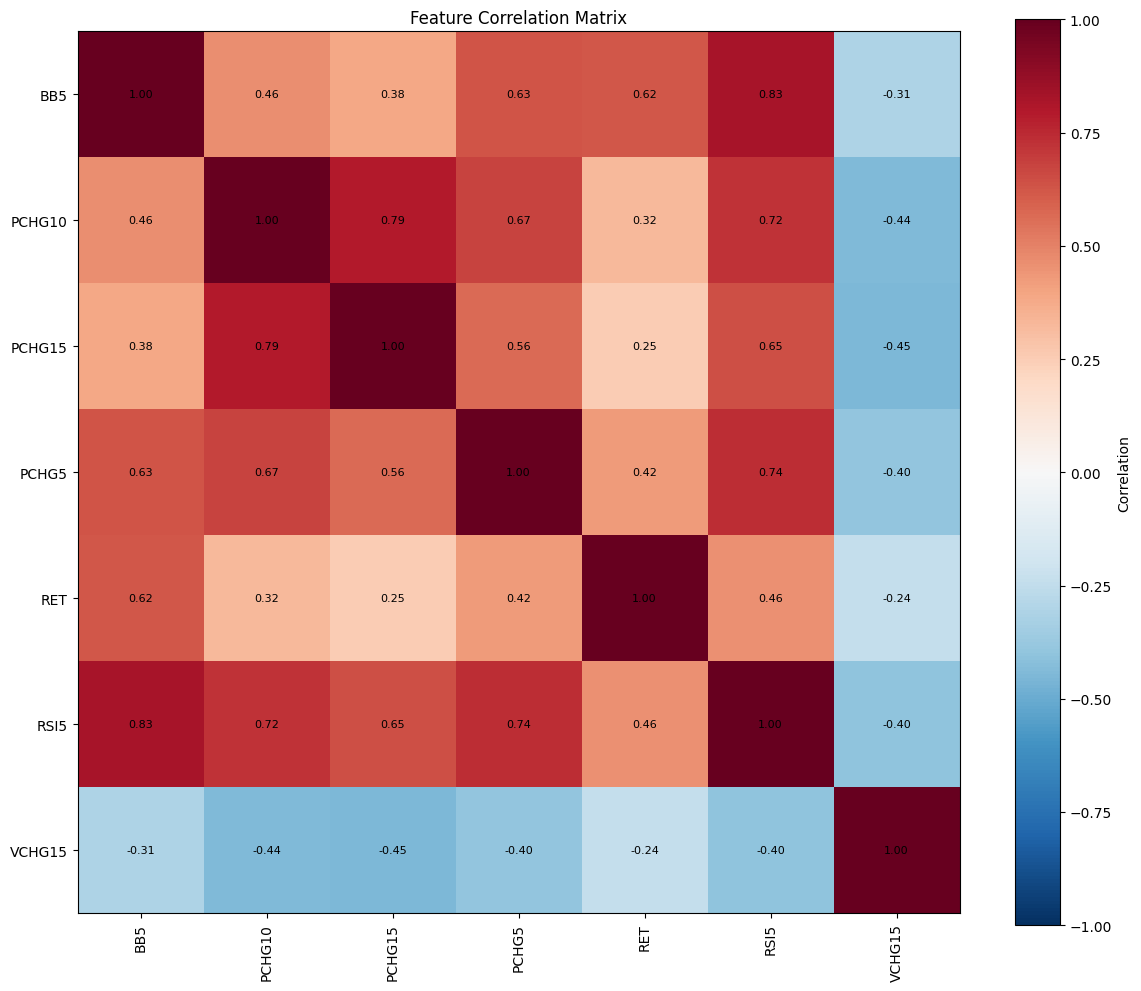

In [7]:
from feature_engineering import FeatureEngineering

FeatureEngineering(
    data_engineering.X_train[data_engineering.features],
    data_engineering.y_train,
    config.feature_selection_methods,
    config.corr_threshold,
    config.n_features,
).plot_correlation_heatmap()

We'll now move to next chapter where I discuss gradient boosting algorithms and employ engineered features in this chapter to predict market moves.

## Q2: Model Building, Tuning, and Benchmarking

In this chapter I focus on modern Gradient Boosting Decision Tree (GBDT) architectures including XGBoost, LightGBM and CatBoost and assess performance of each modelling framework.

### (a) Objective function of GBDT architectures

I'll start with formally defining the mathematical optimization objective function for a GBDT architecture, explicitly highlighting how L1 and L2 regularizations alter the structural tree scores.

#### Additive model and regularized objective

All three libraries build an additive ensemble of regression trees. Even for classification the trees output raw scores (margins) rather than probabilities. At boosting round $t$ the current margin of observation $i$ is updated by the new tree $f_t$ scaled by the learning rate $\eta$:

$$
\hat{z}_{i}^{(t)} = \hat{z}_{i}^{(t-1)} + \eta f_{t}(x_{i}), \qquad f_{t}(x) = w_{q(x)}, \quad q:\mathbb{R}^{d} \to \{1, \dots, T\}, \quad w \in \mathbb{R}^{T}
$$

where $q$ assigns an observation to one of the $T$ leaves of the tree and $w_{j}$ is the score of leaf $j$. The tree is chosen to minimize the regularized objective

$$
\mathcal{L}^{(t)} = \sum_{i=1}^{N} \ell\left(y_{i},\ \hat{z}_{i}^{(t-1)} + f_{t}(x_{i})\right) + \Omega(f_{t})
$$

where $\ell$ is a differentiable loss and $\Omega$ penalizes the complexity of the tree.

**Notation.** $y_{i} \in \{0, 1\}$ is the label of observation $i$ (1 = uptrend). The margin $\hat{z}_{i} \in \mathbb{R}$ is the raw ensemble score, i.e. the sum of the (shrunk) outputs of all trees built so far, $\hat{z}_{i}^{(t-1)} = \hat{z}_{i}^{(0)} + \eta\sum_{k<t} f_{k}(x_{i})$, where $\hat{z}^{(0)}$ is the initial score. It is the predicted log-odds, $\hat{z}_{i} = \ln\frac{p_{i}}{1 - p_{i}}$. The probability of an uptrend is obtained with the sigmoid link

$$
p_{i} = \text{sigm}(\hat{z}_{i}) = \frac{1}{1 + e^{-\hat{z}_{i}}}, \qquad \frac{\partial p_{i}}{\partial \hat{z}_{i}} = p_{i}(1 - p_{i})
$$

and $s_{i} > 0$ is the sample weight (the pipeline uses balanced sample weights computed from the training labels). The weighted logloss of one observation, as a function of its margin, is

$$
\ell_{i}(\hat{z}_{i}) = -s_{i}\left[y_{i}\ln p_{i} + (1 - y_{i})\ln(1 - p_{i})\right] = s_{i}\left[\ln\left(1 + e^{\hat{z}_{i}}\right) - y_{i}\hat{z}_{i}\right]
$$

Differentiating with respect to the margin gives the gradient and the Hessian used by all three libraries:

$$
g_{i} = \frac{\partial \ell_{i}}{\partial \hat{z}_{i}} = s_{i}\left(\frac{e^{\hat{z}_{i}}}{1 + e^{\hat{z}_{i}}} - y_{i}\right) = s_{i}(p_{i} - y_{i}), \qquad h_{i} = \frac{\partial^{2} \ell_{i}}{\partial \hat{z}_{i}^{2}} = s_{i}\,p_{i}(1 - p_{i})
$$

both evaluated at $\hat{z}_{i} = \hat{z}_{i}^{(t-1)}$.

The gradient $g_{i}$ gives the local direction in which the margin should move to lower the loss, while the Hessian $h_{i}$ measures local curvature. It is largest near $p_{i} = 0.5$ and vanishes as $p_{i}$ approaches 0 or 1, so confidently classified observations carry little weight in the tree construction.

#### Second-order approximation and structural tree scores

Regard the per-observation loss as a function of the margin, $\ell_{i}(z)$, and the new tree output $f_{t}(x_{i})$ as a small step $\delta$ away from the current margin $\hat{z}_{i}^{(t-1)}$ (the learning rate $\eta$ is applied afterwards as shrinkage). The second-order Taylor expansion $\ell_{i}(z_{0} + \delta) \approx \ell_{i}(z_{0}) + \ell_{i}'(z_{0})\,\delta + \frac{1}{2}\ell_{i}''(z_{0})\,\delta^{2}$ at $z_{0} = \hat{z}_{i}^{(t-1)}$ and $\delta = f_{t}(x_{i})$ gives

$$
\ell_{i}\left(\hat{z}_{i}^{(t-1)} + f_{t}(x_{i})\right) \approx \ell_{i}\left(\hat{z}_{i}^{(t-1)}\right) + g_{i}f_{t}(x_{i}) + \frac{1}{2}h_{i}f_{t}(x_{i})^{2}
$$

with $g_{i} = s_{i}(p_{i} - y_{i})$ and $h_{i} = s_{i}p_{i}(1 - p_{i})$ from above. Summing over observations and dropping $\sum_{i}\ell_{i}(\hat{z}_{i}^{(t-1)})$, which does not depend on $f_{t}$, gives

$$
\mathcal{L}^{(t)} \approx \sum_{i=1}^{N}\left[g_{i}f_{t}(x_{i}) + \frac{1}{2}h_{i}f_{t}(x_{i})^{2}\right] + \Omega(f_{t})
$$

XGBoost defines the complexity penalty with three components:

$$
\Omega(f) = \gamma T + \frac{1}{2}\lambda\sum_{j=1}^{T}w_{j}^{2} + \alpha\sum_{j=1}^{T}|w_{j}|
$$

where $\gamma$ is a fixed cost per leaf, $\lambda$ is the L2 penalty and $\alpha$ is the L1 penalty on leaf scores. Let $I_{j} = \{i : q(x_{i}) = j\}$ be the observations in leaf $j$, with aggregated derivatives

$$
G_{j} = \sum_{i \in I_{j}} g_{i}, \qquad H_{j} = \sum_{i \in I_{j}} h_{i}
$$

Because the tree output is constant within a leaf, the objective separates by leaf:

$$
\tilde{\mathcal{L}}^{(t)} = \sum_{j=1}^{T}\left[G_{j}w_{j} + \frac{1}{2}(H_{j} + \lambda)w_{j}^{2} + \alpha|w_{j}|\right] + \gamma T
$$

**L2 regularization.** With $\alpha = 0$ the first order condition $G_{j} + (H_{j} + \lambda)w_{j} = 0$ gives the optimal leaf score and the resulting objective:

$$
w_{j}^{*} = -\frac{G_{j}}{H_{j} + \lambda}, \qquad \tilde{\mathcal{L}}^{*} = -\frac{1}{2}\sum_{j=1}^{T}\frac{G_{j}^{2}}{H_{j} + \lambda} + \gamma T
$$

The score is a Newton step $-G_{j}/H_{j}$ multiplied by the shrinkage factor $H_{j}/(H_{j} + \lambda)$. The shrinkage is smooth: scores are pulled towards zero but, unlike under L1, do not become exactly zero unless $G_{j} = 0$ exactly. Each individual gradient $g_{i} = s_{i}(p_{i} - y_{i})$ is never zero because $p_{i} \in (0, 1)$ strictly while $y_{i} \in \{0, 1\}$; $G_{j}$ vanishes only if positive and negative $g_{i}$ cancel within the leaf, which is a non-generic event. The pull is strongest in leaves with small Hessian mass, i.e. leaves supported by few or already confidently classified observations.

**L1 regularization.** The term $\alpha|w_{j}|$ is not differentiable at zero, so the optimality condition is $0 \in G_{j} + (H_{j} + \lambda)w_{j} + \alpha\,\partial|w_{j}|$, where the subdifferential is $\partial|w| = \text{sign}(w)$ for $w \neq 0$ and $\partial|w| = [-1, 1]$ for $w = 0$. The subdifferential of a convex function $f$ at $w_{0}$ is the set of all slopes $c$ of lines through $(w_{0}, f(w_{0}))$ that stay below the graph: $\partial f(w_{0}) = \{c : f(w) \geq f(w_{0}) + c(w - w_{0})\ \forall w\}$. For $w_{0} \neq 0$ the function is differentiable and the only such slope is $\pm 1$. For $w_{0} = 0$ the condition becomes $|w| \geq c\,w$ for all $w$. Taking $w > 0$ gives $c \leq 1$ and taking $w < 0$ gives $c \geq -1$, so every $c \in [-1, 1]$ qualifies. Geometrically, the kink at zero has the left slope $-1$ and the right slope $+1$, and every line through the origin with a slope between them supports the graph from below. At a minimum of a convex function, $0$ must belong to the subdifferential, which gives the optimality condition above. Write $A_{j} = H_{j} + \lambda > 0$ and treat the three cases of the sign of $w_{j}$ separately.

* $w_{j} > 0$: the condition is $G_{j} + A_{j}w_{j} + \alpha = 0$, so $w_{j} = -(G_{j} + \alpha)/A_{j}$. This is consistent with $w_{j} > 0$ only if $G_{j} + \alpha < 0$, i.e. $G_{j} < -\alpha$.
* $w_{j} < 0$: the condition is $G_{j} + A_{j}w_{j} - \alpha = 0$, so $w_{j} = -(G_{j} - \alpha)/A_{j}$. This is consistent with $w_{j} < 0$ only if $G_{j} > \alpha$.
* $w_{j} = 0$: the condition is $0 \in G_{j} + \alpha[-1, 1]$, i.e. $|G_{j}| \leq \alpha$.

The three conditions on $G_{j}$ do not overlap and cover the real line, so exactly one case applies. In the first two cases the score is the L2 solution with the gradient moved towards zero by $\alpha$, that is $G_{j} \mp \alpha = \text{sign}(G_{j})(|G_{j}| - \alpha)$ with $|G_{j}| - \alpha > 0$. In the third case $|G_{j}| - \alpha \leq 0$ and the score is zero. Both situations are written in one formula by the soft-thresholding operator:

$$
w_{j}^{*} = -\frac{T_{\alpha}(G_{j})}{H_{j} + \lambda}, \qquad T_{\alpha}(G) = \text{sign}(G)\max(|G| - \alpha,\ 0)
$$

Equivalently, $w_{j}^{*} = -(G_{j} - \alpha)/(H_{j} + \lambda)$ if $G_{j} > \alpha$, $w_{j}^{*} = -(G_{j} + \alpha)/(H_{j} + \lambda)$ if $G_{j} < -\alpha$ and $w_{j}^{*} = 0$ otherwise. Substituting back, the score of a tree structure becomes

$$
\tilde{\mathcal{L}}^{*} = -\frac{1}{2}\sum_{j=1}^{T}\frac{T_{\alpha}(G_{j})^{2}}{H_{j} + \lambda} + \gamma T
$$

which follows because for $|G_{j}| > \alpha$ the leaf term equals $G_{j}w + \frac{1}{2}A_{j}w^{2} + \alpha|w|$ with $w = -T_{\alpha}(G_{j})/A_{j}$ and $G_{j}w + \alpha|w| = -T_{\alpha}(G_{j})^{2}/A_{j}$, so the term is $-T_{\alpha}(G_{j})^{2}/A_{j} + \frac{1}{2}T_{\alpha}(G_{j})^{2}/A_{j} = -\frac{1}{2}T_{\alpha}(G_{j})^{2}/A_{j}$; for $|G_{j}| \leq \alpha$ the term is $0$. Hence the improvement contributed by a leaf is $\frac{1}{2}T_{\alpha}(G_{j})^{2}/(H_{j} + \lambda)$.

**Leaves with $|G_{j}| \leq \alpha$.** For such a leaf we have $T_{\alpha}(G_{j}) = 0$. Its score is $w_{j}^{*} = 0$, so the tree adds nothing to the margins of the observations in that leaf, and its contribution to the objective is $0$, which is exactly the value of the objective with no leaf-specific correction. The improvement relative to $w_{j} = 0$ is therefore zero: the loss reduction the leaf could offer through its gradient, at most of order $|G_{j}|\,|w|$ for a small step, is smaller than the price $\alpha|w|$ of the L1 penalty for any non-zero $w$, however large $H_{j}$ is. Such a leaf is simply switched off. The three penalties therefore act differently on the tree structure:

* $\lambda$ enlarges the denominator, shrinking every leaf score and every leaf's improvement smoothly.
* $\alpha$ removes $\alpha$ from the gradient mass in the numerator, switching off leaves with weak or noisy signal and producing sparse trees. This matters for daily returns, where the signal-to-noise ratio is low.
* $\gamma$ is a fixed price for adding a leaf, so a split must improve the objective by more than $\gamma$.

For a candidate split of a leaf with statistics $(G, H)$ into left and right children, the gain is

$$
\text{Gain} = \frac{1}{2}\left[\frac{T_{\alpha}(G_{L})^{2}}{H_{L} + \lambda} + \frac{T_{\alpha}(G_{R})^{2}}{H_{R} + \lambda} - \frac{T_{\alpha}(G)^{2}}{H + \lambda}\right] - \gamma
$$

and the split is useful when the gain is positive and both children satisfy the minimum Hessian requirement. For $\alpha = 0$ this reduces to the L2-only gain. As an illustration take a leaf with $G = -3$ and $H = 10$, where the leaf improvement is $S = \frac{1}{2}T_{\alpha}(G)^{2}/(H + \lambda)$:

| $\lambda$ | $\alpha$ | Leaf score $w^{*}$ | Leaf improvement $S$ |
|---|---|---|---|
| 0 | 0 | 0.3000 | 0.4500 |
| 1 | 0 | 0.2727 | 0.4091 |
| 5 | 0 | 0.2000 | 0.3000 |
| 10 | 0 | 0.1500 | 0.2250 |

Increasing $\lambda$ with $\alpha = 0$ lowers the score gradually. Fixing $\lambda = 1$ and increasing $\alpha$:

| $\lambda$ | $\alpha$ | Leaf score $w^{*}$ | Leaf improvement $S$ |
|---|---|---|---|
| 1 | 0 | 0.2727 | 0.4091 |
| 1 | 1 | 0.1818 | 0.1818 |
| 1 | 2 | 0.0909 | 0.0455 |
| 1 | 3 | 0.0000 | 0.0000 |

Here $\alpha = 3 = |G|$ removes the leaf completely.

#### XGBoost

XGBoost uses the objective above without modification. Its penalties are `reg_lambda` ($\lambda$, default 1), `reg_alpha` ($\alpha$, default 0) and `gamma` ($\gamma$), while `min_child_weight` is the minimum Hessian sum $H$ required in a child. Trees are grown level by level up to `max_depth`. The search space in `config.cfg` covers `reg_alpha` $\in \{0, 0.01, 0.1, 1, 5\}$, `reg_lambda` $\in \{1, 5, 10, 20, 50\}$ and `gamma` $\in \{0, 0.1, 0.2, 0.3, 0.4\}$.

#### LightGBM

LightGBM minimizes the same second-order objective with $\Omega(f) = \lambda_{1}\sum_{j}|w_{j}| + \frac{1}{2}\lambda_{2}\sum_{j}w_{j}^{2}$, where $\lambda_{1}$ is `lambda_l1` and $\lambda_{2}$ is `lambda_l2` (both default 0). Its leaf score and split gain have the same form as in XGBoost. LightGBM's Gain is not halved and is compared with `min_gain_to_split` directly, whereas XGBoost compares the same un-halved quantity with $\gamma$ (the $\frac{1}{2}$ appears only in the objective-reduction derivation):

$$
w_{j}^{*} = -\frac{T_{\lambda_{1}}(G_{j})}{H_{j} + \lambda_{2}}, \qquad \text{Gain} = \frac{T_{\lambda_{1}}(G_{L})^{2}}{H_{L} + \lambda_{2}} + \frac{T_{\lambda_{1}}(G_{R})^{2}}{H_{R} + \lambda_{2}} - \frac{T_{\lambda_{1}}(G)^{2}}{H + \lambda_{2}}
$$

There is no explicit $\gamma T$ term. Instead a split is performed only if its gain exceeds `min_gain_to_split` and both children satisfy `min_data_in_leaf` and `min_sum_hessian_in_leaf` (minimum $H$), while the tree size is capped by `num_leaves`. LightGBM grows the tree leaf-wise, expanding the leaf with the largest gain. Because $\lambda_{1}$ and $\lambda_{2}$ enter the gain, they also change which leaf is expanded next: a leaf with $|G| \leq \lambda_{1}$ has zero gain and is never selected.

#### CatBoost

CatBoost penalizes leaf scores with L2 only:

$$
\Omega(f) = \frac{1}{2}\lambda\sum_{j=1}^{T}w_{j}^{2}
$$

where $\lambda$ is `l2_leaf_reg` (default 3). There is no L1 term and no per-leaf cost $\gamma$, so the soft-thresholding above is not available: leaf scores are always shrunk by the factor $H_{j}/(H_{j} + \lambda)$ but never set exactly to zero. CatBoost estimates leaf values with Newton steps (one iteration by default, `leaf_estimation_iterations=1`),

$$
w_{j} = -\frac{G_{j}}{H_{j} + \lambda}
$$

Trees are symmetric (oblivious): every node of a level uses the same split, so a tree of depth $D$ has $T = 2^{D}$ leaves and its complexity is controlled by `depth` rather than by $\gamma$ or a minimum gain. Splits are scored jointly over all leaves of a level using `score_function` (default Cosine). Gradients are computed with the standard (`Plain`) scheme by default; this exam instead sets `boosting_type='Ordered'` together with `has_time=True`, which is discussed in part (b).

### (b) Hyperparameter tuning

#### Consistent search space

One shared grid (defined in `config.cfg`) is mapped to each library's parameter names, so that every model is searched over the same regularization and capacity range wherever the libraries have a comparable parameter. All models are tuned and compared in the same way:

1. The data are split chronologically: the first $80\%$ of days is the training sample and the last $20\%$ the test sample.
2. Hyperparameters are tuned on the training sample only, with a `RandomizedSearchCV` of $150$ draws per model, scored by ROC-AUC on a `TimeSeriesSplit` with $5$ expanding-window folds and a gap of $1$ day. The label of day $t$ uses the close of day $t+1$, so a one-day gap keeps the labels of the training fold from overlapping the validation fold. Class-balanced sample weights are used when fitting.
3. The best candidate is refitted on the whole training sample and evaluated once on the untouched test sample.

The scoring objective is the same in all three libraries (binary logistic loss for fitting, ROC-AUC for selection), and the random seed is $42$ everywhere.

| Concept | Shared grid | XGBoost | LightGBM | CatBoost | Rationale |
|----------|-------------------------------------|-----------------------|-----------------------|---------------------|---------------|
| Learning rate | $\{0.01, 0.03, 0.05, 0.07, 0.09\}$ | `learning_rate` | `learning_rate` | `learning_rate` | identical shrinkage $\eta$ |
| Number of trees | $\{100, 200, 300\}$ | `n_estimators` | `n_estimators` | `iterations` | same boosting budget |
| Tree depth | $\{1,\dots,5\}$ | `max_depth` | `max_depth` | `depth` | a depth-$D$ tree has at most $2^{D}$ leaves |
| Column fraction | $\{0.4, 0.6, 0.8, 1\}$ | `colsample_bytree` | `colsample_bytree` | `rsm` | same share of features considered per tree (CatBoost: per split) |
| Row fraction | $\{0.7, 0.8, 0.9, 1\}$ | `subsample` | `subsample`| NA | row sampling; not tuned for CatBoost |
| Split randomization | $\{0, 0.5, 1, 2\}$ | NA | NA | `random_strength` | CatBoost only; noise added to split scores |
| L2 penalty $\lambda$ | $\{1, 5, 10, 20, 50\}$ | `reg_lambda` | `reg_lambda` | `l2_leaf_reg` | same $\lambda$ in $H + \lambda$ |
| L1 penalty $\alpha$ | $\{0, 0.01, 0.1, 1, 5\}$ | `reg_alpha` | `reg_alpha` | NA | CatBoost has no L1 term |
| Split cost $\gamma$ | $\{0, 0.1, 0.2, 0.3, 0.4\}$ | `gamma` | `min_split_gain` $= \gamma$ | NA | both compare $S_{L} + S_{R} - S$ with the threshold (see below) |
| Minimum Hessian in a child | $\{1, 3, 5, 7\}$ | `min_child_weight` | `min_child_weight` | NA | same quantity $H_{\text{child}}$ |

Parameters that a library does not have are left out rather than approximated, so the CatBoost grid is smaller and the LightGBM grid larger. The scikit-learn names `reg_alpha`, `reg_lambda`, `min_split_gain` and `min_child_weight` used for XGBoost and LightGBM are aliases of the native names `lambda_l1`, `lambda_l2`, `min_gain_to_split` and `min_sum_hessian_in_leaf` used in part (a).

**Fixed settings (not tuned).** XGBoost: `objective='binary:logistic'`, `tree_method='hist'`. LightGBM: `objective='binary'`, `boosting_type='gbdt'`, and the library defaults `num_leaves=31` and `min_child_samples=20`. CatBoost: `loss_function='Logloss'`, `grow_policy='SymmetricTree'`, `boosting_type='Ordered'` and `has_time=True` (see below). The `eval_metric`/`metric` entries only name the monitored metric; no validation set or early stopping is used, so the number of trees is chosen by the search, not by early stopping. All libraries use a fixed seed $42$ and all available cores (`n_jobs=-1`, CatBoost `thread_count=-1`).

**Capacity is controlled by depth only.** `num_leaves` stays at its default of $31$. Since a depth-$D$ tree has at most $2^{D}$ leaves, `max_depth` $\leq 4$ is the binding cap and `max_depth` $= 5$ is limited marginally by $31 < 32$ leaves, so the three libraries are searched over the same capacity range.

**Search coverage.** $100$ draws is an equal computing budget, not equal coverage of the search space. CatBoost's search is the densest as its search grid is narrower, which favours it slightly, and the conclusions below should be read as a comparison of tuned models under an equal budget rather than of fully optimized models.

#### Leaf-wise (LightGBM) versus level-wise (XGBoost) split selection

Let $S(G,H) = \dfrac{T_{\lambda_{1}}(G)^{2}}{H+\lambda_{2}}$ be the leaf score, with $T_{\lambda_{1}}(G)=\operatorname{sign}(G)\max(|G|-\lambda_{1},0)$ (for XGBoost $\lambda_{1}=\alpha$, $\lambda_{2}=\lambda$). For a leaf $\ell$ with sums $(G_{\ell},H_{\ell})$ and a candidate split $s$ (feature and threshold) into children $L$ and $R$, the gain is

$$
\Delta(\ell,s) = S(G_{L},H_{L}) + S(G_{R},H_{R}) - S(G_{\ell},H_{\ell}),
$$

and the reduction of the regularized objective is $\tfrac{1}{2}\Delta(\ell,s)-\gamma$. Both libraries take the best threshold inside a leaf, $\Delta^{*}(\ell)=\max_{s}\Delta(\ell,s)$, subject to the minimum-Hessian and minimum-data constraints. They differ in which leaf is expanded.

**XGBoost, level-wise.** Every leaf of the current level $\mathcal{L}_{d}$ is judged on its own gain:

$$
\text{split } \ell \in \mathcal{L}_{d} \iff \Delta^{*}(\ell) > 2\gamma \quad (d < \texttt{max\_depth}),
$$

so $|\mathcal{L}_{d+1}| \leq 2|\mathcal{L}_{d}|$ and the tree has at most $2^{D}$ leaves. A leaf with a small gain is still expanded if it clears $\gamma$, because the decision does not depend on the other leaves.

**LightGBM, leaf-wise (best-first).** At step $m$ the tree has leaf set $\mathcal{L}^{(m)}$ with $|\mathcal{L}^{(m)}| = m+1$. The leaf expanded next is the one with the largest best gain among the eligible leaves of the whole tree, i.e. those still below the depth cap:

$$
\ell^{(m)} = \arg\max_{\ell \in \mathcal{L}^{(m)}_{\text{elig}}} \Delta^{*}(\ell), \qquad \mathcal{L}^{(m)}_{\text{elig}}=\{\ell \in \mathcal{L}^{(m)}:\ \text{depth}(\ell)<\texttt{max\_depth}\},
$$

$$
\text{stop if } \Delta^{*}\big(\ell^{(m)}\big) \leq \texttt{min\_gain\_to\_split}, \ \text{ or } \ |\mathcal{L}^{(m)}| = \texttt{num\_leaves}, \ \text{ or } \ \mathcal{L}^{(m)}_{\text{elig}}=\varnothing.
$$

Here `max_depth` bounds the depth of each branch and `num_leaves` bounds the total leaf count; whichever binds first ends growth. In this exam `num_leaves` stays at $31$, so `max_depth` is the effective cap (see above).


Each step is the greedy choice of the single split that lowers the training loss most. For a budget of $M$ leaves, a level-wise tree spends splits on every leaf of a level, including low-gain ones, whereas leaf-wise growth skips them in favour of the highest-gain leaves. The leaf-wise path therefore reaches a given training-loss reduction with fewer leaves (a greedy statement, not a global-optimality claim). The price is an unbalanced, deeper tree whose depth is not bounded by $\log_{2}M$ and which fits noise more easily; this is why `max_depth` and `min_child_samples` are used to cap capacity. Since $\lambda_{1},\lambda_{2}$ enter $S$, they change $\Delta^{*}(\ell)$ and hence the ranking of leaves, and a leaf with $|G_{\ell}| \leq \lambda_{1}$ has zero score and is never chosen.

#### CatBoost: Target Statistics without look-ahead bias

A naive target statistic for a categorical feature $x^{i}$ uses all observations, $\hat{x}_{k}^{i}=\dfrac{\sum_{j=1}^{n}\mathbb{1}[x_{j}^{i}=x_{k}^{i}]\,y_{j}}{\sum_{j=1}^{n}\mathbb{1}[x_{j}^{i}=x_{k}^{i}]}$. It contains $y_{k}$ itself (and future labels), so $\mathbb{E}[\hat{x}_{k}^{i}\mid y_{k}] \neq \mathbb{E}[\hat{x}_{k}^{i}]$: target leakage. CatBoost fixes an ordering $\sigma$ of the observations and computes the statistic of example $k$ only from the examples that precede it:

$$
\hat{x}_{\sigma(k)}^{i} = \frac{\sum_{j:\,\sigma(j)<\sigma(k)} \mathbb{1}\big[x_{j}^{i}=x_{k}^{i}\big]\,y_{j} + a\,p}{\sum_{j:\,\sigma(j)<\sigma(k)} \mathbb{1}\big[x_{j}^{i}=x_{k}^{i}\big] + a},
$$

where $p$ is a prior (for example the mean of $y$) and $a>0$ its weight, which stabilizes categories with few preceding observations. The statistic of $k$ depends only on $x_{k}$ and on $\{(x_{j},y_{j}):\sigma(j)<\sigma(k)\}$, so $\hat{x}_{\sigma(k)}^{i} \perp y_{k} \mid x_{k}$ and the training-time feature has the same conditional distribution as a test-time feature.

With `has_time=True`, $\sigma$ is the chronological order, $\sigma(j)<\sigma(k) \iff t_{j}<t_{k}$, instead of a random permutation. The statistic and the gradient for day $t$ are then built only from days before $t$, the information set available in real time. All features in this exam are numeric, so there are no categorical Target Statistics to compute and the effect here comes through ordered boosting; the leak-free evaluation still rests on the chronological split and the gapped `TimeSeriesSplit` described above.


In [8]:
for boosting_algo in config.boosting_algorithms:
    display(Markdown(f"**Best parameters for {boosting_algo}:**"))
    show_table(pd.DataFrame(best_parameters[boosting_algo], index=[0]), floatfmt="g", fontsize="scriptsize")

**Best parameters for xgboost:**

|   subsample |   reg_lambda |   reg_alpha |   n_estimators |   min_child_weight |   max_depth |   learning_rate |   gamma |   colsample_bytree |
|------------:|-------------:|------------:|---------------:|-------------------:|------------:|----------------:|--------:|-------------------:|
|         0.9 |           20 |         0.1 |            200 |                  5 |           1 |            0.01 |     0.1 |                  1 |

**Best parameters for lightgbm:**

|   subsample |   reg_lambda |   reg_alpha |   n_estimators |   min_split_gain |   min_child_weight |   max_depth |   learning_rate |   colsample_bytree |
|------------:|-------------:|------------:|---------------:|-----------------:|-------------------:|------------:|----------------:|-------------------:|
|         0.7 |           10 |         0.1 |            200 |                0 |                  3 |           1 |            0.01 |                0.8 |

**Best parameters for catboost:**

|   rsm |   random_strength |   learning_rate |   l2_leaf_reg |   iterations |   depth |
|------:|------------------:|----------------:|--------------:|-------------:|--------:|
|   0.6 |                 1 |            0.01 |            10 |          200 |       1 |

### (c) Model metrics and trading strategies

#### Metric definitions

All metrics are computed out-of-sample on the final 20% of the chronologically ordered data ($N = 840$ days). The positive class $y = 1$ is an uptrend label and the classifier output $\hat{y} = \mathbf{1}[p > 0.5]$ is used for threshold-based metrics. From the confusion matrix

$$
\begin{pmatrix} TN & FP \\ FN & TP \end{pmatrix}, \qquad TP + FP + FN + TN = N,
$$

we define

$$
\text{Accuracy} = \frac{TP + TN}{N}, \qquad \text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall (TPR)} = \frac{TP}{TP + FN},
$$

$$
\text{Specificity (TNR)} = \frac{TN}{TN + FP}, \qquad \text{FPR} = \frac{FP}{FP + TN}, \qquad F_{1} = \frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision} + \text{Recall}},
$$

$$
\text{Balanced accuracy} = \frac{1}{2}\left(\text{TPR} + \text{TNR}\right).
$$

Balanced accuracy is reported because the classes are imbalanced (the base rate of $y = 1$ in the test set is $282/840 = 0.336$), so plain accuracy rewards predicting the majority class. The classification report gives precision, recall and $F_{1}$ for each class.

The ROC curve plots $\text{TPR}(\tau)$ against $\text{FPR}(\tau)$ as the threshold $\tau$ on $p$ varies, and the precision-recall curve plots $\text{Precision}(\tau)$ against $\text{Recall}(\tau)$. The area under the ROC curve is threshold-free and equals the probability that a random positive is ranked above a random negative (Mann-Whitney form):

$$
\text{AUC} = \int_{0}^{1}\text{TPR}\,d(\text{FPR}) = \frac{1}{n_{+}n_{-}}\sum_{i:\,y_{i}=1}\;\sum_{k:\,y_{k}=0}\left(\mathbf{1}[p_{i} > p_{k}] + \tfrac{1}{2}\mathbf{1}[p_{i} = p_{k}]\right),
$$

with $\text{AUC} = 0.5$ for a random ranking. Overfitting is measured by the train-test gap $\text{BA}_{\text{train}} - \text{BA}_{\text{test}}$ of balanced accuracy. For trading, precision is the hit rate of executed long trades, and the lift over the base rate is $\text{Precision}/\pi_{+}$ with $\pi_{+} = 0.336$.

**Model metrics:**

|                         |   xgboost |   lightgbm |   catboost |
|:------------------------|----------:|-----------:|-----------:|
| train_accuracy          |    0.5365 |     0.5448 |     0.5397 |
| test_accuracy           |    0.5357 |     0.5345 |     0.5369 |
| train_balanced_accuracy |    0.5715 |     0.5762 |     0.5696 |
| test_balanced_accuracy  |    0.5604 |     0.5578 |     0.5552 |
| roc_auc                 |    0.5862 |     0.5895 |     0.5900 |
| f1                      |    0.4800 |     0.4766 |     0.4707 |
| precision               |    0.3854 |     0.3836 |     0.3827 |
| recall                  |    0.6360 |     0.6290 |     0.6113 |

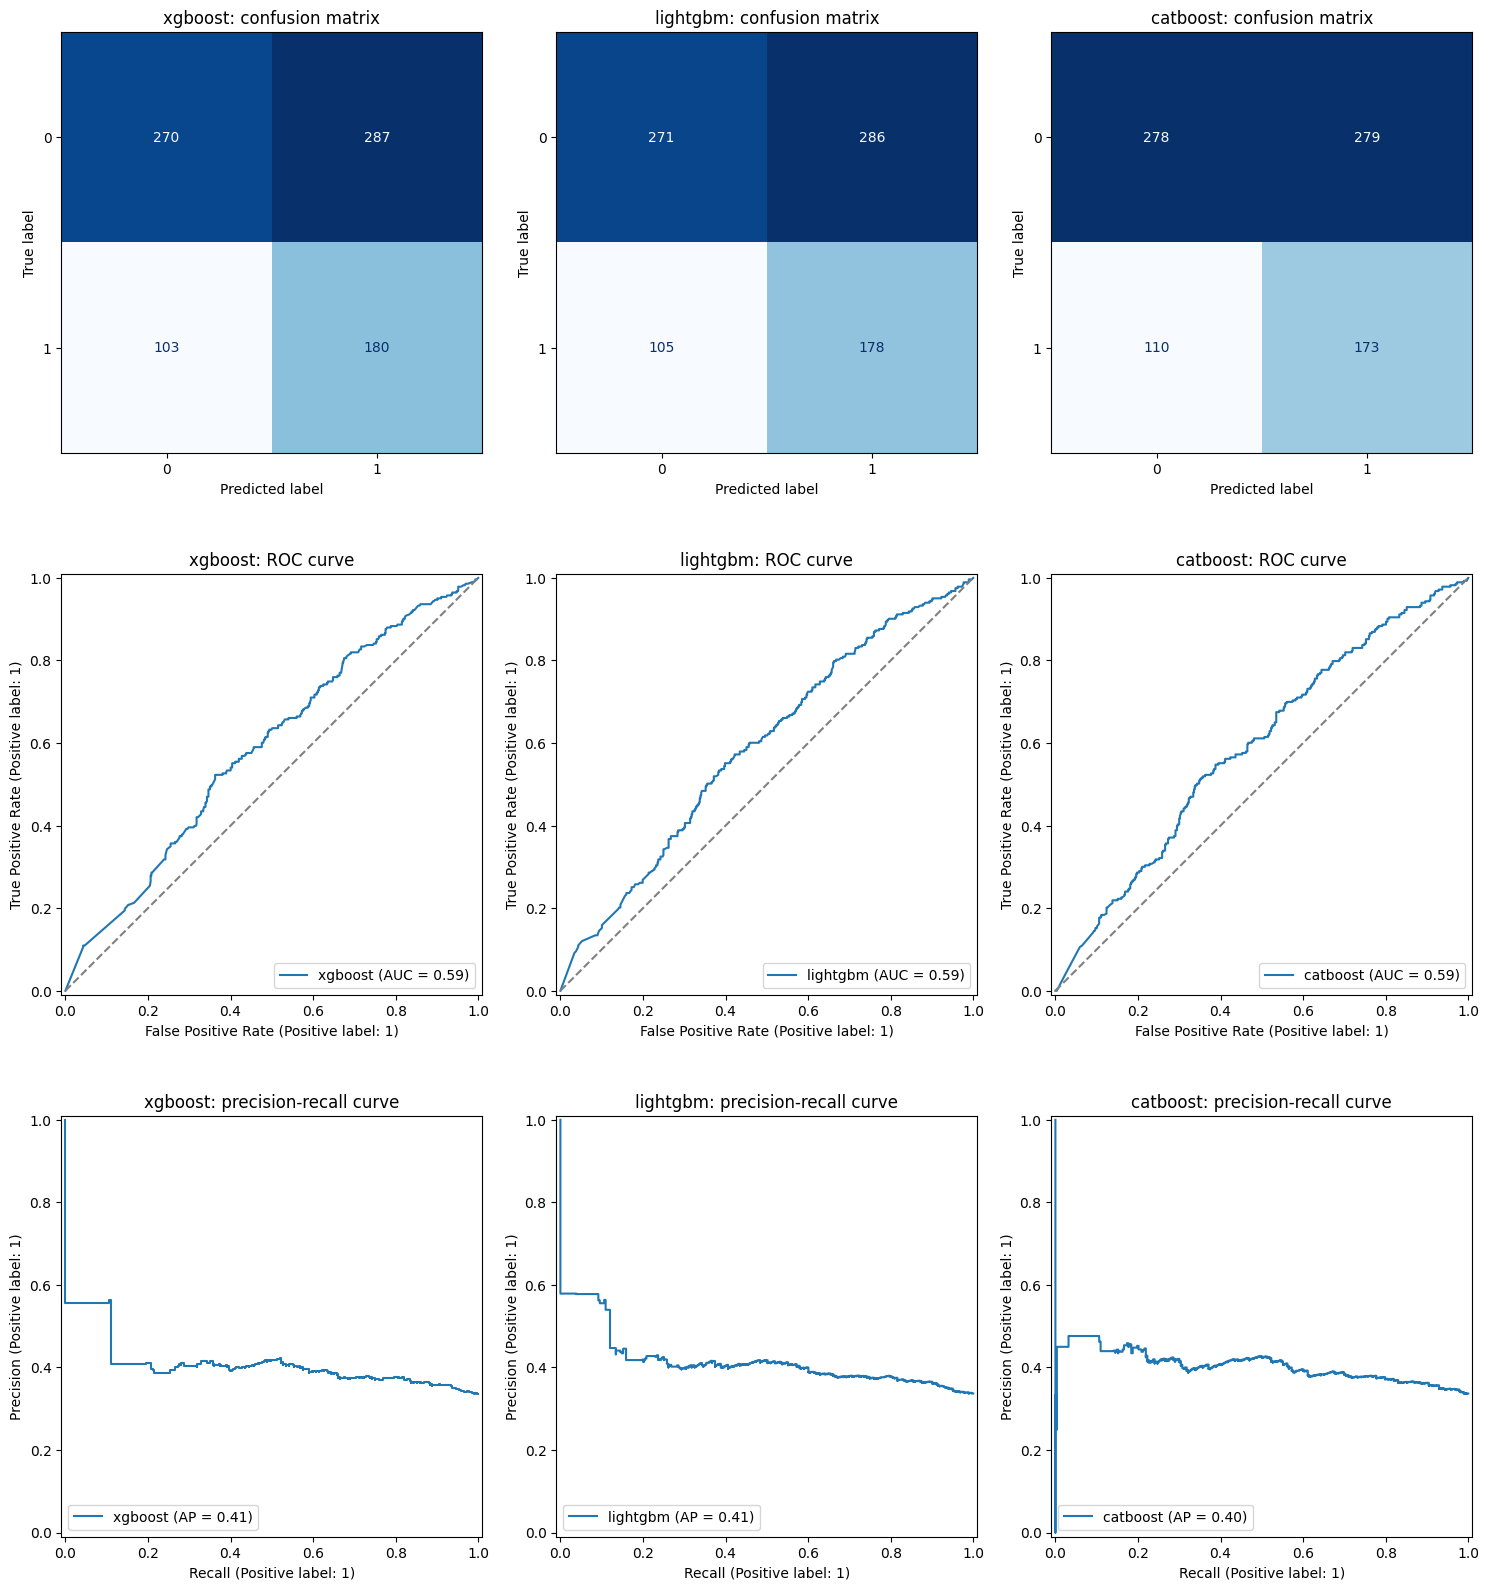

In [9]:
display(Markdown("**Model metrics:**"))
show_table(pd.DataFrame(metrics), index=True)

MLClassifier.plot_evaluation_grid(classifiers)

#### Interpretation and recommendation

**Predictive power.** All three models carry a weak but consistent out-of-sample signal. Test AUC is 0.586 (XGBoost), 0.590 (LightGBM) and 0.590 (CatBoost), against 0.5 for a random ranking, and test balanced accuracy is 0.555-0.560. Plain accuracy (about 0.535 for XGBoost) is below the 0.664 obtained by always predicting the majority class. Plain accuracy is below the majority-class baseline, so it indicates that the model does not improve overall classification accuracy at the 0.5 threshold; AUC and balanced accuracy provide evidence of a weak ranking signal. The three algorithms are almost indistinguishable: the differences in AUC (0.004) and balanced accuracy (0.005) are far smaller than the sampling noise on 840 daily observations.

**Precision-recall trade-off.** At the 0.5 threshold the models are recall-oriented: recall is 0.61-0.64 but precision is only 0.38-0.39, so roughly six in ten long signals are false positives. Precision is about 1.14 times the base rate of 0.336 (0.385/0.336), a modest lift. The models flag too many days as uptrends (time in market is about 54-56%) and do not separate strong up-days from noise sharply. Raising the probability threshold would increase precision at the cost of recall, and the best threshold depends on trading costs and risk appetite.

**Stability and risk.** The train-test balanced accuracy gap is small: 0.011 (XGBoost), 0.018 (LightGBM) and 0.014 (CatBoost), so overfitting is limited and the tuned, regularised models generalise. XGBoost has the smallest gap and the best test balanced accuracy, F1 (0.480) and recall. As long/flat strategies, however, all three underperform Buy-and-Hold out-of-sample (Sharpe 0.55-0.68 against 1.22). The paired block bootstrap shows the Sharpe shortfall is significant, with the 95% confidence interval for the difference excluding zero for every model. Position changes (about 180) also reduce Sharpe further once a 1bp cost is applied. The strategies have a slightly lower volatility and maximum drawdown, but this does not compensate for the lost return during a strong bull market.

**Recommendation.** XGBoost is the preferred candidate: it has the highest test balanced accuracy, F1 and recall, the smallest train–test balanced-accuracy gap, and the strongest strategy Sharpe of the three. However, the models’ performance differences are small, and none of the tested long/flat strategies outperformed Buy-and-Hold; therefore, XGBoost should not be deployed as a stand-alone timing strategy at the 0.5 cutoff. Its modestly above-random AUC suggests potential value as an input to a broader strategy, such as gradual position sizing, but first verify probability calibration and develop the sizing rule using validation data, then assess it with walk-forward tests and realistic trading costs. As a further research direction, test categorical features that identify bearish market conditions, ensuring they use only information available at the time of each prediction.


### Trading strategy assessment

Each model is converted into a long/flat strategy: the position on day $t$ is $s_{t} = \hat{y}_{t} \in \{0, 1\}$ and the strategy log return is $r^{S}_{t+1} = s_{t}\,r_{t+1}$, where $r_{t+1} = \ln(P_{t+1}/P_{t})$ is the SPY log return. The benchmark is Buy-and-Hold, $s_{t} \equiv 1$. Results are for the out-of-sample period only and, unless stated, ignore transaction costs. With $\bar{r}$ and $\sigma$ the mean and standard deviation of daily returns and $252$ trading days per year:

$$
\text{Sharpe} = \sqrt{252}\,\frac{\bar{r}}{\sigma}, \qquad \text{Sortino} = \sqrt{252}\,\frac{\bar{r}}{\sigma_{d}}, \quad \sigma_{d}^{2} = \frac{1}{n}\sum_{t}\min(r_{t}, 0)^{2},
$$

$$
    \text{MaxDD} = \min_{t}\left(C_{t} - \max_{u \leq t}C_{u}\right), \quad C_{t} = \sum_{k \leq t}r_{k}.
$$

Cumulative return $C_{T}$ and drawdown are therefore expressed in log points, consistent with the `Total_Return` and `Max_Drawdown` figures computed by the pipeline.

|                       |   Buy-and-Hold |   xgboost |   lightgbm |   catboost |
|:----------------------|---------------:|----------:|-----------:|-----------:|
| Cumulative log return |         0.6010 |    0.3046 |     0.2624 |     0.2401 |
| Annualised return     |         0.1803 |    0.0914 |     0.0787 |     0.0720 |
| Annualised volatility |         0.1483 |    0.1338 |     0.1335 |     0.1319 |
| Sharpe                |         1.2160 |    0.6830 |     0.5897 |     0.5463 |
| Sortino               |         1.7858 |    0.9928 |     0.8515 |     0.7869 |
| Max drawdown          |        -0.2107 |   -0.1969 |    -0.2046 |    -0.1969 |
| Time in market        |         1.0000 |    0.5560 |     0.5524 |     0.5381 |
| Position changes      |         0.0000 |  180.0000 |   187.0000 |   179.0000 |
| Sharpe (1bp cost)     |         1.2160 |    0.6426 |     0.5477 |     0.5055 |

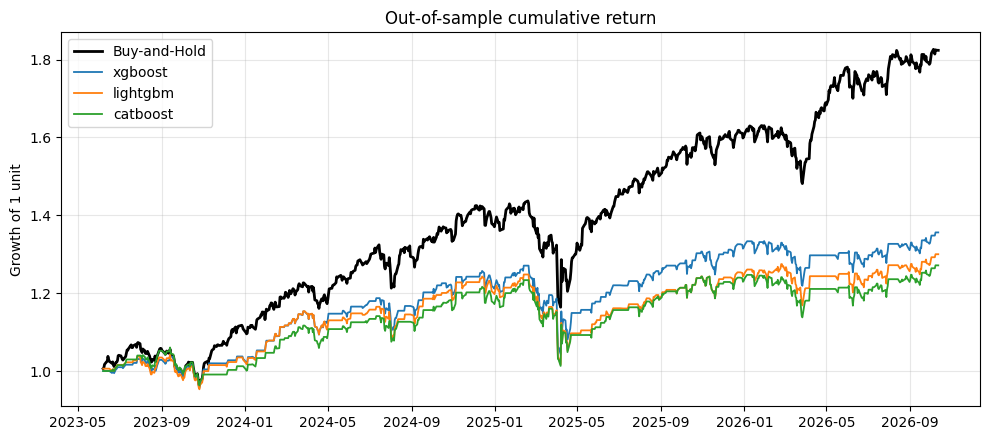

**Paired block bootstrap of Sharpe(strategy) minus Sharpe(Buy-and-Hold):**

|                    |   xgboost |   lightgbm |   catboost |
|:-------------------|----------:|-----------:|-----------:|
| Sharpe diff vs B&H |    -0.533 |     -0.626 |     -0.670 |
| 95% CI low         |    -1.005 |     -1.139 |     -1.220 |
| 95% CI high        |    -0.071 |     -0.152 |     -0.149 |
| P(diff > 0)        |     0.007 |      0.004 |      0.004 |

In [10]:
import matplotlib.pyplot as plt
import numpy as np

ann = 252

def perf(r, pos=None, cost=0.0):
    r = np.asarray(r, dtype=float)
    if pos is not None and cost:
        r = r - cost * np.abs(np.diff(pos, prepend=pos[0]))
    wealth = np.cumsum(r)
    dd = (wealth - np.maximum.accumulate(wealth)).min()
    downside = np.sqrt(np.mean(np.minimum(r, 0) ** 2))
    return {
        "Cumulative log return": wealth[-1],
        "Annualised return": ann * r.mean(),
        "Annualised volatility": np.sqrt(ann) * r.std(ddof=1),
        "Sharpe": np.sqrt(ann) * r.mean() / r.std(ddof=1),
        "Sortino": np.sqrt(ann) * r.mean() / downside,
        "Max drawdown": dd,
    }

first_clf = next(iter(classifiers.values()))
first = first_clf.signal
ret = first["tomorrow_returns"].to_numpy()
table = {"Buy-and-Hold": {**perf(ret), "Time in market": 1.0, "Position changes": 0, "Sharpe (1bp cost)": perf(ret)["Sharpe"]}}
series = {"Buy-and-Hold": ret}

for algo, clf in classifiers.items():
    sig = clf.signal
    pos = sig["Signal"].to_numpy()
    r = sig["Strategy"].to_numpy()
    table[algo] = {**perf(r), "Time in market": pos.mean(), "Position changes": int(np.abs(np.diff(pos)).sum()),
                   "Sharpe (1bp cost)": perf(r, pos, 1e-4)["Sharpe"]}
    series[algo] = r
show_table(pd.DataFrame(table), floatfmt=".4f", index=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
dates = first.index
styles = {"Buy-and-Hold": dict(lw=2, color="black")}
for name, r in series.items():
    ax.plot(dates, np.exp(np.cumsum(r)), label=name, **styles.get(name, dict(lw=1.3)))
ax.set_ylabel("Growth of 1 unit"); ax.set_title("Out-of-sample cumulative return"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

rng = np.random.default_rng(42)
n, block, B = len(ret), 20, 2000
starts_n = int(np.ceil(n / block))
def sharpe(x): return np.sqrt(ann) * x.mean() / x.std(ddof=1)
diffs = {a: [] for a in classifiers}
for _ in range(B):
    idx = np.concatenate([np.arange(s, s + block) for s in rng.integers(0, n - block + 1, starts_n)])[:n]
    for a in classifiers:
        diffs[a].append(sharpe(series[a][idx]) - sharpe(ret[idx]))
boot = {a: {"Sharpe diff vs B&H": table[a]["Sharpe"] - table["Buy-and-Hold"]["Sharpe"],
            "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5), "P(diff > 0)": np.mean(np.array(d) > 0)}
        for a, d in diffs.items()}
display(Markdown("**Paired block bootstrap of Sharpe(strategy) minus Sharpe(Buy-and-Hold):**"))
show_table(pd.DataFrame(boot), floatfmt=".3f", index=True)

#### Conclusion

The gradient-boosting models show modest out-of-sample discrimination: AUC is about 0.59 and balanced accuracy is 0.555–0.560. XGBoost is marginally strongest on several metrics, but the three models perform similarly, and the results do not establish a meaningful winner. The tuning grid is limited relative to the number of hyperparameters; broader tuning could be explored, subject to computational cost and a validation design that avoids overfitting.

This modest classification signal did not translate into stronger performance under the tested long/flat rules at a 0.5 cutoff. Their cumulative log returns were 0.24–0.30 versus 0.60 for Buy-and-Hold, and their Sharpe ratios were 0.55–0.68 versus 1.22. The paired block-bootstrap intervals for the Sharpe differences were below zero, indicating underperformance relative to Buy-and-Hold in this test period. Accordingly, these results do not support using the models as stand-alone timing strategies or as a replacement for passive SPY exposure. Their scores could be investigated as inputs to a broader strategy, but calibration, position sizing, additional features and any resulting trading rule would need to be validated out of sample with realistic costs.


### Appendix

The features are computed as follows:

$$
\begin{aligned}
GAP_t &= \frac{O_t}{C_{t-1}} - 1 \\
RET_t &= \ln\frac{C_t}{C_{t-1}} \\
PCHG_{X,t} &= \frac{C_t}{C_{t-X}} - 1 \\
VCHG_{X,t} &= \frac{V_t}{V_{t-X}} - 1 \\
RET_{X,t} &= \sum_{i=0}^{X-1} RET_{t-i} = \ln\frac{C_t}{C_{t-X}} \\
GAP_{X,t} &= \frac{1}{X}\sum_{i=0}^{X-1} GAP_{t-i} \\
STD_{X,t} &= \sqrt{\frac{1}{X-1}\sum_{i=0}^{X-1}\left(RET_{t-i} - \overline{RET}_{X,t}\right)^2} \\
BB_{X,t} &= \frac{C_t - LB_{X,t}}{UB_{X,t} - LB_{X,t}}, \quad LB_{X,t} = SMA_X(C)_t - 2\sigma_X(C)_t, \quad UB_{X,t} = SMA_X(C)_t + 2\sigma_X(C)_t \\
RSI_{X,t} &= 100 - \frac{100}{1 + RS_{X,t}}, \quad RS_{X,t} = \frac{AvgGain_{X,t}}{AvgLoss_{X,t}} \\
STOCH_{X,t} &= 100\,\frac{C_t - Lmin_{X,t}}{Hmax_{X,t} - Lmin_{X,t}}, \quad Hmax_{X,t} = \max_{i<X} H_{t-i}, \quad Lmin_{X,t} = \min_{i<X} L_{t-i}
\end{aligned}
$$

RSI inputs are the gains and losses of the close:

$$
Gain_t = \max(C_t - C_{t-1}, 0), \qquad Loss_t = \max(C_{t-1} - C_t, 0)
$$

$$
AvgGain_{X,t} = \frac{(X-1)\,AvgGain_{X,t-1} + Gain_t}{X}, \qquad AvgLoss_{X,t} = \frac{(X-1)\,AvgLoss_{X,t-1} + Loss_t}{X}
$$

Notation: $O_t$ = open; $C_t$ = close; $H_t$ = high; $L_t$ = low; $V_t$ = volume; $X$ = lookback window (trading days). $\sum$ is a sum over the $X$-day window; $SMA_X$ is its simple moving average. All return-type features (GAP, PCHG, VCHG, RET) are expressed as decimals, not percentages.

Notes: STDX uses sample standard deviation (ddof=1); BBX bands use price standard deviation, not return volatility. RSI uses the chosen gain/loss smoothing convention (e.g., Wilder). Guard against zero denominators and use consistent split-adjusted OHLC prices.

RSI note: AvgGain and AvgLoss use Wilder-style exponential smoothing ($\alpha = 1/X$), initialized from the first $X$ price changes. The stochastic oscillator parameter smooth_window=1 means no smoothing of %K; it does not change the RSI formula.